In [4]:
%load_ext autoreload
%autoreload 2

In [5]:
# Quimb imports
import quimb.tensor as qtn

# Qiskit imports
import qiskit as qk

# General imports
import json
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

# JAX-like import
import jax
import optax
from jax import config
from jax import numpy as jnp
config.update("jax_enable_x64", True)

# Custom imports
import mpo_utils
import noise_channels
import tn_simulate_qpt
from lpdo_utils import build_lpdo, lpdo_to_mpo
import lpdo_utils
import training_functions
from training_functions import optimize_tn, optimize_trace_preservation
import dataset_utils

seed = 331
rnd_key = jax.random.PRNGKey(seed)
np.random.seed(seed)

# Training

In [6]:
######################################
# IMPORT EXPERIMENTAL TRAINING DATA
######################################
#data_file = 'cluster_data/expdata_cxeven_nq16_ns100_globalRS_sic_states_1000_2023-10-05'
#data_file = 'cluster_data/expdata_cxeven_nq16_ns100_globalRS_sic_states_100_2023-10-09'
#data_file = 'cluster_data/expdata_cxeven_nq16_ns1000_globalRS_sic_states_1000_2023-09-28'
# data_file = 'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns100000_global_repeated_sic_states_2023-10-11'
#data_file = 'cluster_data/expdata_cxeven_nq10_ns144000_local2_sic_states_1000_2023-10-11'
# data_file = 'cluster_data/expdata_cxeven_nq10_ns1000_globalRS_sic_states_1000_2023-10-11'
#data_file = 'cluster_data/expdata_cxeven_nq10_ns1000_globalRS_sic_states_1000_2023-10-13'
# data_file = 'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns1000_global_repeated_sic_states_2026-05-06.json'
data_file= 'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns1000000_global_repeated_sic_states_TEST_2026-05-06.json'
with open(data_file) as f:
    exp_data = json.load(f)

qasm_qc, noise_str = exp_data['qc'], exp_data['noise']
experiments = {'states': exp_data['states'], 'povms': exp_data['povms'], 'counts': exp_data['counts']}
print("Noise model:", noise_str)

# Ideal unitary / quantum circuit (noise-free)
qc = qk.QuantumCircuit.from_qasm_str(qasm_qc)
num_qubits = qc.num_qubits
print("Ideal quantum circuit:")
print(qc)

######################################
# BUILD GROUND-TRUTH NOISE LPDO
######################################
true_lpdo = noise_channels.select_noise_channel(noise_str, tensor_type = 'lpdo', num_qubits = num_qubits)
true_mpo = noise_channels.select_noise_channel(noise_str, tensor_type = 'mpo', num_qubits = num_qubits)
print("||MPO[simulation] - MPO[LPDO]||:", lpdo_to_mpo(true_lpdo).distance(true_mpo))
true_lpdo

Noise model: noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s
Ideal quantum circuit:
          
q_0: ──■──
     ┌─┴─┐
q_1: ┤ X ├
     └───┘
q_2: ──■──
     ┌─┴─┐
q_3: ┤ X ├
     └───┘
q_4: ──■──
     ┌─┴─┐
q_5: ┤ X ├
     └───┘
q_6: ──■──
     ┌─┴─┐
q_7: ┤ X ├
     └───┘
q_8: ──■──
     ┌─┴─┐
q_9: ┤ X ├
     └───┘
||MPO[simulation] - MPO[LPDO]||: 2.1579186437577746e-05


LPDOSuperOperator1D(tensors=20, indices=68, L=10, max_bond=64)

+0.000033312358 [best: +0.000033312358] : : 1076it [00:00, 1104.68it/s]                        
/Users/francesco.grieco/.local/share/mamba/envs/tn/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Tr[LPDO] = (1024.0014438601338+0j) (=1024?)


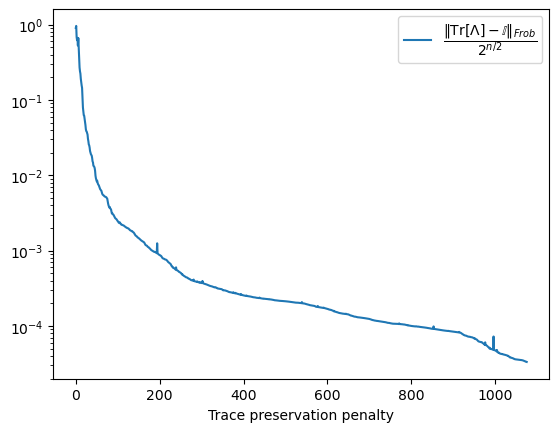

In [7]:
########################################################
# INITIAL PARAMETERS AND TENSOR NETWORK STRUCTURE
########################################################
virtual_bd = 2
kraus_bd = 4
init_lpdo = build_lpdo(num_qubits=num_qubits, 
                       virtual_bd=virtual_bd, 
                       kraus_bd=kraus_bd, 
                       init_method='normal_complex')

# Bring initial LPDO close to a physical channel by making it trace preserving
init_lpdo, tnopt = optimize_trace_preservation(init_lpdo, 
                                               optimizer='L-BFGS-B', 
                                               steps=1000, 
                                               return_lpdo=True, 
                                               plot_results=True)

print(f"Tr[LPDO] = {lpdo_utils.trace_lpdo(init_lpdo)} (={2**num_qubits}?)")

Prepare dataset for training:
1. created the lightcone marginals if needed,
2. divide in batches,
3. creates batches of tensor networks

In [8]:
########################################################
# PROCESS DATASET
########################################################
batch_size = 250
build_marginals=None

counts = exp_data['counts']
states = exp_data['states']
povms = exp_data['povms']

batched_hyper_tns, batched_params_tns, batched_skeletons_tns = dataset_utils.create_training_dataset(counts, states, povms, 
                                                                                                     batch_size=batch_size, 
                                                                                                     shuffle=True, 
                                                                                                     build_marginals=build_marginals, 
                                                                                                     evolve_with_unitary=qc)

processed_experiments_dict = {'batched_hyper_tns': batched_hyper_tns,
                              'batched_params_tns': batched_params_tns,
                              'batched_skeletons_tns': batched_skeletons_tns}

exp_dataset = processed_experiments_dict['batched_params_tns'], processed_experiments_dict['batched_skeletons_tns'][0]

Shots = (1000000, 2, 10)
> Step 2/3: creating batches of data from experiments
> Step 3/3: creating tensor network representation of batches and evolving them


100%|██████████| 4000/4000 [00:21<00:00, 184.93it/s]


In [7]:
########################################################
# TRAINING HYPERPARAMETERS
########################################################
epochs = 5
optimizer = optax.adam(learning_rate=1e-4)

# Extract initial params and tensor network structure of the trainable Kraus Operators ("half" of the LPDO, the other half is the transposed conjugate)
kraus_tn = init_lpdo.select('V')

########################################################
# START TRAINING LOOP
########################################################
res = optimize_tn(exp_dataset, 
                  kraus_tn, 
                  optimizer, 
                  true_lpdo=true_lpdo,
                  epochs=epochs)

Dataset:
 > Training batches = 3950
 > Test batches = 50
 > Batch size = 250



Epoch  1/5 — Batch Loss: 5.541992 || Test Loss: 5.5506802 — Frob. distance: 0.1319357 — Tr[LPDO]: 1028.89+0.00j: 100%|██████████| 3950/3950 [00:08<00:00, 478.44it/s]
Epoch  2/5 — Batch Loss: 5.498119 || Test Loss: 5.5174405 — Frob. distance: 0.0059771 — Tr[LPDO]: 1025.54+0.00j: 100%|██████████| 3950/3950 [00:07<00:00, 527.75it/s]
Epoch  3/5 — Batch Loss: 5.493794 || Test Loss: 5.5151539 — Frob. distance: 0.0011817 — Tr[LPDO]: 1024.86+0.00j: 100%|██████████| 3950/3950 [00:07<00:00, 529.39it/s]
Epoch  4/5 — Batch Loss: 5.492461 || Test Loss: 5.5146287 — Frob. distance: 0.0004776 — Tr[LPDO]: 1024.54+0.00j: 100%|██████████| 3950/3950 [00:07<00:00, 535.12it/s]
Epoch  5/5 — Batch Loss: 5.491933 || Test Loss: 5.5144148 — Frob. distance: 0.0003080 — Tr[LPDO]: 1024.50-0.00j: 100%|██████████| 3950/3950 [00:07<00:00, 525.04it/s]


+0.000067713365 [best: +0.000067713365] :  46%|████▌     | 1147/2500 [00:00<00:01, 1253.62it/s]


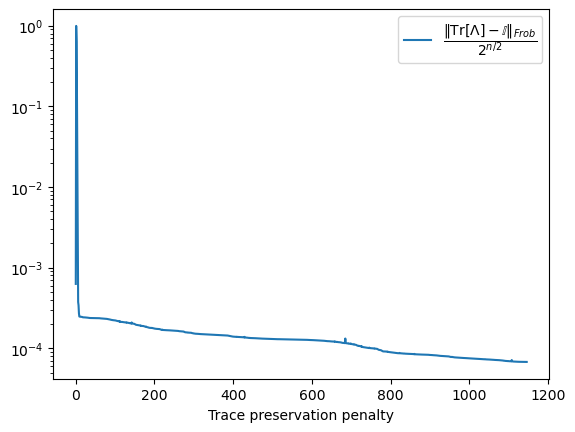

In [8]:
best_idx =  np.argmin(res['test_loss'])
best_params = res['params'][best_idx]
opt_lpdo = build_lpdo(tn_data = best_params.values())

# Bring initial LPDO close to a physical channel by making it trace preserving
opt_lpdo_TP, tnopt = optimize_trace_preservation(opt_lpdo, 
                                                optimizer='L-BFGS-B', 
                                                steps = 2500, 
                                                return_lpdo=True, 
                                                plot_results=True)

In [9]:
p, s = qtn.pack(opt_lpdo_TP.select(['V']))
print(training_functions.compute_metrics(p, (s, 0, 0), true_lpdo = true_lpdo))

p, s = qtn.pack(opt_lpdo.select(['V']))
print(training_functions.compute_metrics(p, (s, 0, 0), true_lpdo = true_lpdo))

{'frob_distance': Array(0.00038361, dtype=float64), 'lpdo_trace': Array(1023.99926228-1.5726234e-14j, dtype=complex128), 'test_loss': None}
{'frob_distance': Array(0.00030799, dtype=float64), 'lpdo_trace': Array(1024.49724755-2.07568265e-14j, dtype=complex128), 'test_loss': None}


In [10]:
def save_results(res: dict, file_name: str, file_folder: str =  'opt_results/'):
    """
    Save results of the function 'optimize_tn' in json format. 
    Complex values are transformed into strings for json serialisation.
    """
    from datetime import datetime
    #today = datetime.today().strftime('%Y-%m-%d')
    save_dict = res.copy()
    with open(file_folder + file_name + '.json', 'w') as file:
        save_dict['params'] = [{k: np.array(v, dtype=str).tolist() for k, v in p.items()} for p in save_dict['params']]
        save_dict['lpdo_trace'] = np.array(save_dict['lpdo_trace'], dtype=str).tolist()
        json.dump(save_dict, file, indent = 4)

save_results(res, file_name=data_file)

FileNotFoundError: [Errno 2] No such file or directory: 'opt_results//Users/francesco.grieco/Library/CloudStorage/OneDrive-Algorithmiq/Desktop/sabrina/cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns1000000_global_repeated_sic_states_TEST_2026-05-06.json.json'

In [11]:
res['train_loss']

[np.float64(7.063451549874934),
 np.float64(5.557017789043584),
 np.float64(5.522009277909564),
 np.float64(5.519324563635162),
 np.float64(5.518610400650492),
 np.float64(5.51836770867674)]

<>:15: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:20: SyntaxWarning: "\|" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\|"? A raw string is also an option.
<>:24: SyntaxWarning: "\L" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\L"? A raw string is also an option.
<>:15: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:20: SyntaxWarning: "\|" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\|"? A raw string is also an option.
<>:24: SyntaxWarning: "\L" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\L"? A raw string is also an option.
/var/folders/g9/lcpd651j0l70vzr038j9yrw40000gn/T/ipykernel_37597/4062073117.

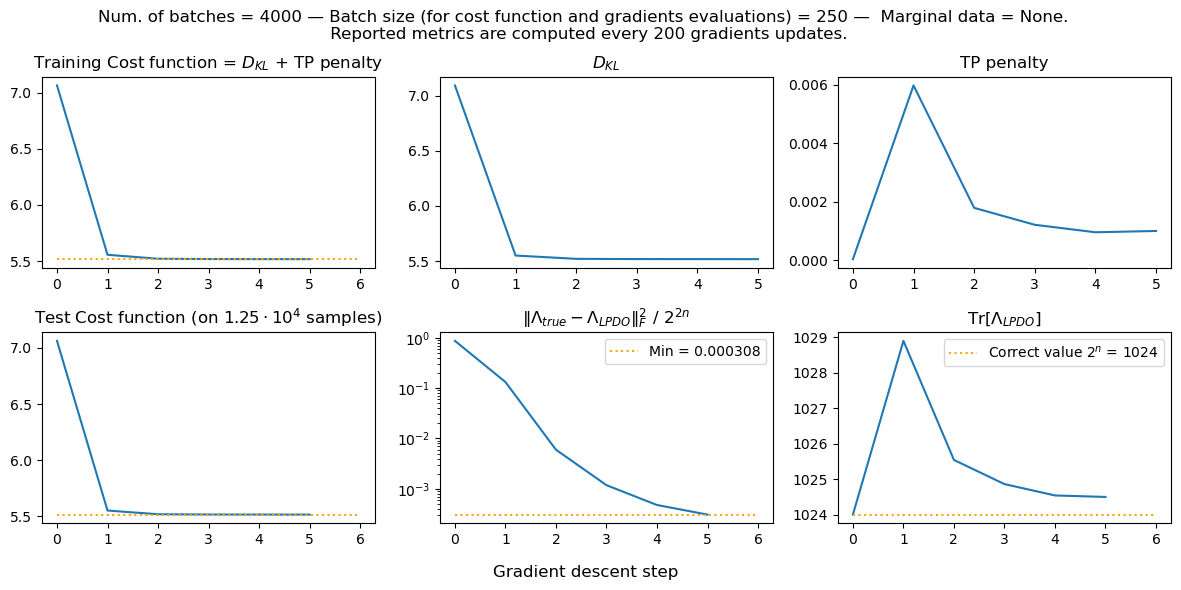

In [13]:
fig, axs = plt.subplots(2, 3, figsize = (12,6))

axs[0,0].plot(res['train_loss'])
axs[0,0].hlines(min(res['train_loss']), 0, len(res['train_loss']), ls = ":", color='orange', label = f"Min = {round(min(res['train_loss']), 6)}")
axs[0,0].set_title("Training Cost function = $D_{KL}$ + TP penalty")

axs[0,1].plot(res['nll'])
axs[0,1].set_title("$D_{KL}$")

axs[0,2].plot(res['distance_to_tp'])
axs[0,2].set_title("TP penalty")

axs[1,0].plot(res['test_loss'], label = "Test Loss")
axs[1,0].hlines(min(res['test_loss']), 0, len(res['test_loss']), ls = ":", color='orange', label = f"Min = {round(min(res['test_loss']), 6)}")
axs[1,0].set_title("Test Cost function (on $1.25 \cdot 10^4$ samples)")

axs[1,1].plot(res['frob_distance'])
axs[1,1].hlines(min(res['frob_distance']), 0, len(res['frob_distance']),  ls = ":", color='orange', label = f"Min = {round(min(res['frob_distance']), 6)}")
axs[1,1].set_yscale('log')
axs[1,1].set_title("$\|\Lambda_{true}-\Lambda_{LPDO}\|^2_F~/~2^{2n}$")
axs[1,1].legend()

axs[1,2].plot(res['lpdo_trace'])
axs[1,2].set_title("Tr$[\Lambda_{LPDO}]$")
axs[1,2].hlines(2**num_qubits, 0, len(res['lpdo_trace']),  ls = ":", color='orange', label = f"Correct value $2^n$ = {2**num_qubits}")
axs[1,2].legend()


fig.suptitle(f"Num. of batches = {len(batched_hyper_tns)} — Batch size (for cost function and gradients evaluations) = {batch_size} —  Marginal data = {build_marginals}. \n Reported metrics are computed every 200 gradients updates.", y=0.97)
fig.supxlabel("Gradient descent step", y=0.02)
plt.tight_layout()

#plt.savefig(f"imgs/" + data_file + 'LOCAL' + str(build_marginals) + ".png", format='png', dpi = 300)

[[-0.03014217+0.22221144j  0.02385252-0.07475377j]
 [ 0.02791791+0.06418818j  0.03130191+0.26231272j]]


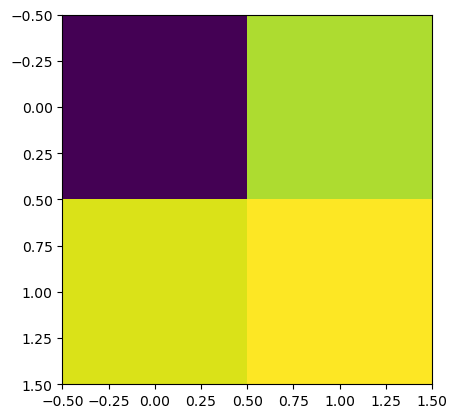

In [14]:
opt_lpdo = build_lpdo(tn_data = res['params'][-1].values())
print(np.array(opt_lpdo['V'][0].data[0,0]))
plt.imshow(np.array(opt_lpdo['V'][0].data[0,0]).real)

In [20]:
143 * 4

572

In [21]:
anna = jax.tree_util.tree_map(lambda _: jnp.round(_, 5), qtn.pack(opt_lpdo.select(['V']))[0])
anna = build_lpdo(tn_data = anna.values())    
lpdo_utils.lpdo_fidelity(anna, true_lpdo)

Array(0.86784818, dtype=float64)

In [22]:
opt_params = res['params'][-1]
opt_lpdo = build_lpdo(tn_data = opt_params.values())  
lpdo_utils.lpdo_fidelity(opt_lpdo, true_lpdo)  

Array(0.86784818, dtype=float64)

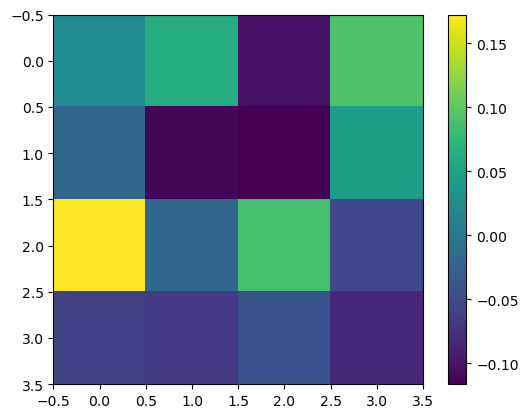

In [23]:
opt_params = res['params'][-1]
opt_lpdo = build_lpdo(tn_data = opt_params.values())           
opt_mpo = lpdo_to_mpo(opt_lpdo)

plt.imshow(opt_mpo[1].data[1][0].real)
plt.imshow(opt_mpo[1].data[1][0].imag)
plt.colorbar()

TypeError: Image data of dtype object cannot be converted to float

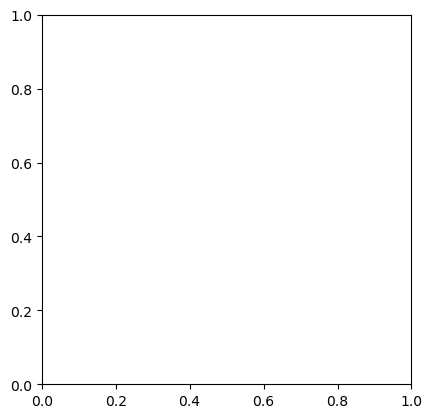

: 

In [ ]:
# BUILD SUPEROPERATOR
opt_lpdo = build_lpdo(tn_data = res['params'][-1].values())
opt_lpdo

left_inds  = [f'bn{_}' for _ in range(num_qubits)] + [f'kn{_}' for _ in range(num_qubits)]
right_inds = [f'b{_}' for _ in range(num_qubits)] + [f'k{_}' for _ in range(num_qubits)]
opt_superop = opt_lpdo.contract()#.to_dense(left_inds, right_inds)

plt.imshow(opt_superop)
plt.colorbar()

# Analysis

In [1]:
def load_results(file_name: str, file_folder: str =  'opt_results/'):
    """
    Save results of the function 'optimize_tn' in json format. 
    Complex values are transformed into strings for json serialisation.
    """
    with open(file_folder + file_name, 'r') as file:
        res = json.load(file)
        res['params'] = [{int(k): np.array(v, dtype=complex) for k, v in p.items()} for p in res['params']]
        res['lpdo_trace'] = np.array(res['lpdo_trace'], dtype=complex)
    return res

file_name = 'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns100000_global_repeated_sic_states_2023-10-11_2023-10-11.json'
res = load_results(file_name=file_name)

opt_params = res['params'][-1]
opt_lpdo = build_lpdo(tn_data = opt_params.values())           
opt_mpo = lpdo_to_mpo(opt_lpdo)

opt_mpo_compressed = opt_mpo.compress_all_simple(max_bond=4)

print(opt_mpo.distance(true_mpo), opt_mpo_compressed.distance(true_mpo), opt_mpo.distance(opt_mpo_compressed))
opt_mpo

FileNotFoundError: [Errno 2] No such file or directory: 'opt_results/cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns100000_global_repeated_sic_states_2023-10-11_2023-10-11.json'

In [26]:
bond_dim = 4
num_sweeps = 10
inv_opt_mpo, e1 = mpo_utils.invert_mpo(opt_mpo_compressed, bond_dim, num_sweeps, canonize_while_sweeping=True, dtype=complex)

: 

In [ ]:
bond_dim = 8
num_sweeps = 1

inv_opt_mpo = qtn.MatrixProductOperator(inv_opt_mpo.arrays, upper_ind_id='k{}', lower_ind_id='b{}', site_tag_id='I{}')
inv_opt_mpo =  mpo_utils.variational_inversion_mpo(opt_mpo, virtual_bd = bond_dim, warmstart_mpo = inv_opt_mpo, 
                                                       optimisation_method='global', optimizer='L-BFGS-B', steps = 1000, num_sweeps=num_sweeps)
#mpo_utils.mpo_to_params_file(inv_opt_mpo, 'inv_opt_mpo' + data_file)

In [ ]:
bond_dim = 4
num_sweeps = 1
inv_true_mpo, e2 = mpo_utils.invert_mpo(true_mpo, bond_dim, num_sweeps, dtype=float)
#inv_true_mpo = qtn.MatrixProductOperator(inv_true_mpo.arrays, upper_ind_id='k{}', lower_ind_id='b{}', site_tag_id='I{}')

#mpo_utils.mpo_to_params_file(inv_true_mpo, 'inv_true_mpo' + data_file)
# inv_mpo = mpo_utils.mpo_from_params_file('inv_params_mpo_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s.json')

In [ ]:
inv_true_mpo.distance(inv_opt_mpo)

In [ ]:
true_mpo.distance(opt_mpo)

In [ ]:
inv_opt_mpo.get_params()[0].astype(str)

In [ ]:
inv_opt_mpo.get_params()

In [ ]:
def save_mpo_params(mpo: dict, file_name: str):
    """
    Save results of the function 'optimize_tn' in json format. 
    Complex values are transformed into strings for json serialisation.
    """
    with open(file_name + '.json', 'w') as file:
        mpo_params = [{k: np.array(v, dtype=str).tolist() for k, v in p.items()} for p in mpo]
        json.dump(mpo_params, file, indent = 4)

save_results(res, file_name=data_file)

In [ ]:
true_lpdo = noise_channels.select_noise_channel(noise_str, tensor_type = 'lpdo', num_qubits = num_qubits)
true_mpo = noise_channels.select_noise_channel(noise_str, tensor_type = 'mpo', num_qubits = num_qubits)
print("‖ MPO[exact] - MPO[LPDO] ‖ = ", lpdo_to_mpo(true_lpdo).distance(true_mpo))

opt_lpdo = build_lpdo(tn_data = res['params'][-1].values())
opt_mpo = lpdo_to_mpo(opt_lpdo)
print(lpdo_utils.trace_lpdo(opt_lpdo))

opt_lpdo_tp, _ = optimize_trace_preservation(opt_lpdo, steps = 500)
print(lpdo_utils.trace_lpdo(opt_lpdo_tp))

def mpo_element(mpo, alpha, beta, state_space = 4):
    if len(alpha) != len(beta):
        raise ValueError("Indices defined on different number of qubits!")
    else:
        if len(mpo.tensors) != len(alpha):
            raise ValueError("Qubit number mismatch between the MPO and the provided indices")
    inp = qtn.MPS_product_state(tn_simulate_qpt.labels_to_tensors(alpha, state_space=state_space)).reindex_all(mpo.lower_ind_id)
    out = qtn.MPS_product_state(tn_simulate_qpt.labels_to_tensors(beta, state_space=state_space)).reindex_all(mpo.upper_ind_id)
    return (inp & mpo & out).contract()

alpha = np.random.randint(0, high=4, size=num_qubits)
beta  = alpha #np.random.randint(0, high=16, size=num_qubits)

a = mpo_element(true_mpo, alpha, beta)
b = mpo_element(lpdo_to_mpo(true_lpdo), alpha, beta)
c = mpo_element(lpdo_to_mpo(opt_lpdo), alpha, beta)
d = mpo_element(lpdo_to_mpo(opt_lpdo_tp), alpha, beta)

print("True MPO from Pauli-Lindblad coefficients =", a)
print("True MPO from Kraus probabilities (from LPDO) =", b)
print("Opt. MPO after training (from LPDO) =", c)
print("Opt. MPO after training and TP optimisazion (from LPDO) =", d)
print("Single element difference=", a-b)
print("Norm of the MPOs difference =", true_mpo.distance(lpdo_to_mpo(true_lpdo)))
print("Norm of the MPOs difference =", true_mpo.distance(lpdo_to_mpo(opt_lpdo)))
print("Norm of the MPOs difference =", true_mpo.distance(lpdo_to_mpo(opt_lpdo_tp)))

In [ ]:
qtn.MPS_product_state(tn_simulate_qpt.labels_to_tensors(alpha, state_space=4)).reindex_all(mpo.lower_ind_id)

In [ ]:
batched_hyper_tns = dataset_utils.batch_and_evolve_experiments(experiments, evolve_states_with = None, batch_size = 50, shuffle = False)
batched_hyper_tns_params = [(qtn.pack(state)[0], qtn.pack(povm)[0]) for state, povm in batched_hyper_tns]    
_, batch_state_skeleton = qtn.pack(batched_hyper_tns[0][0])
_, batch_povm_skeleton = qtn.pack(batched_hyper_tns[0][1])

kraus_params, kraus_skeleton = qtn.pack(kraus_tn)
skeletons = (kraus_skeleton, batch_state_skeleton, batch_povm_skeleton)

batch_in_state, batch_out_povm = batched_hyper_tns_params[0]
#training_functions.loss_fn(kraus_params, batch_in_state, batch_out_povm, skeletons)

In [ ]:
anna = jax.value_and_grad(training_functions.loss_fn, has_aux=True)

test_lpdo = build_lpdo(tn_data=res['params'][0].values())
kraus_tn = test_lpdo.select('V')
kraus_params, _ = qtn.pack(kraus_tn)
np.mean(anna(kraus_params, batch_in_state, batch_out_povm, skeletons)[1][14])

In [ ]:
import collections

In [ ]:
anna = collections.deque(maxlen=3)
[anna.append(_) for _ in range(32)]
np.mean(anna)

In [ ]:
np.mean(anna)